# Monte Carlo prediction and control: implementation

Blackjack played by simulation only: first-visit Monte Carlo (MC) prediction of a fixed policy's values, then MC control by exploring starts and by an epsilon-soft policy, each checked against exact dynamic programming (DP) over the blackjack dynamics.
Companion to the chapter note: [Monte Carlo prediction and control](../chapters/05a%20Monte%20Carlo%20prediction%20and%20control.md).

**Sections**
1. The blackjack game and the dealer's exact outcomes
2. The exact answer by dynamic programming
3. First-visit Monte Carlo prediction
4. The error shrinks as one over the square root of the sample size
5. Monte Carlo control with exploring starts
6. On-policy first-visit Monte Carlo control with an epsilon-soft policy
7. Checkpoints

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_GAME, SEED_PREDICT, SEED_ES, SEED_SOFT = 1, 2, 3, 4
STICK, HIT = 0, 1
CARD_VALUES = np.arange(1, 11)  # ace counts 1 or 11; every face card counts 10
P_CARD = np.array([1 / 13] * 9 + [4 / 13])  # infinite deck: the same probabilities on every draw
SUMS = np.arange(12, 22)  # player sums with a decision to make
N_STATES, N_PAIRS = 200, 400  # (sum, dealer card, usable ace) and the same with an action
FIXED_STICK = 20
P_HIT_FIXED = np.broadcast_to((SUMS < FIXED_STICK).astype(float)[:, None, None], (10, 10, 2))
CHUNK = 1 << 16  # random numbers drawn per batch by the streams
N_DEALER = 100_000
N_SMALL, N_LARGE = 10_000, 500_000  # episodes for the two prediction snapshots (the book's counts)
N_GRID = (10_000, 20_000, 50_000, 100_000, 200_000, 500_000)  # sample sizes for the error-rate check
MIN_VISITS = 30  # a state enters the error-rate check if it expects this many visits at N_SMALL
N_RUNS = 3  # independent seeds per control method
N_ES, N_SOFT = 1_000_000, 6_000_000  # episodes per control run
EPS = 0.1  # exploration probability of the epsilon-soft policy
SNAPSHOT_EVERY = 20_000  # episodes between policy snapshots in the control runs
REPORT_ES, REPORT_SOFT = 100_000, 500_000  # episodes between the printed mistake counts
Z_LIMIT = 3  # standardized errors and noise allowances are measured in this many standard errors
DEALER_Z_LIMIT = 4  # looser limit for the 20 dealer comparisons, which are many
Z_SHARE_MIN = 0.97  # share of well-visited states that must have |z| below Z_LIMIT
RMSE_RATIO_TOL = 0.25  # observed against predicted RMSE; about 4 times its sampling error
SLOPE_TOL = 0.1  # log-log slope of the error against the sample size around -0.5
ES_RETURN_TOL = 0.002  # expected-return shortfall of the ES policy, about 5% of the optimum's loss
SOFT_RETURN_TOL = 0.001  # same for the epsilon-soft policy played with exploration
MISTAKE_VISIT_SHARE = 0.02  # visits a method may spend in states where its policy is wrong

## 1. The blackjack game and the dealer's exact outcomes

The player and the dealer each get two cards; one dealer card is face up (the dealer's *showing* card). Cards come from an infinite deck, so every draw is independent: an ace has probability 1/13, each of 2 to 9 has 1/13, and a 10 (the ten and the three face cards) has 4/13.

- **Counting:** an ace counts 11 if that does not push the sum over 21 (a *usable ace*), otherwise 1.
- **Natural:** a player whose first two cards are an ace and a 10 has a natural and wins, unless the dealer also has one, which is a draw. Naturals end the game at once.
- **Player:** hits (takes a card) or sticks (stops). Going over 21 is bust and loses. Sums below 12 are always hit, so decisions exist only for sums 12 to 21.
- **Dealer:** sticks on any sum of 17 or more, otherwise hits. A soft 17 (an ace counted as 11) is already a sum of 17, so the dealer sticks on it: the rule taken literally. Dealer bust means the player wins; otherwise the closer sum to 21 wins and equal sums draw.
- **No peeking:** when the player has no natural, a dealer natural does not end the game early; the player still plays and can bust. If the player sticks on a non-natural 21 against a dealer natural, the sums are equal and it is a draw.
- **Rewards:** +1 win, -1 loss, 0 draw, all given at the end of the game; there is no discounting ($\gamma = 1$), so the reward is the return $G$.

The decision state is (player sum, dealer's showing card, usable ace): 10 x 10 x 2 = 200 states.
One game is one episode. It never visits the same state twice, because the sum only grows (and a usable ace can only be lost), so every visit is a first visit.

Because the dealer's rule is fixed, its final total can be computed exactly for each showing card. This gives a first check that the simulator is right.

In [2]:
def card_stream(rng: np.random.Generator):
    """Endless iterator of cards drawn with replacement (a deck with infinite cards)."""
    while True:
        yield from np.minimum(rng.integers(1, 14, CHUNK), 10).tolist()


def total(h: int, ace: bool) -> int:
    """Best sum of a hand with hard total `h` (all aces counted 1) that holds an ace or not."""
    return h + 10 if ace and h + 10 <= 21 else h


def dealer_play(up: int, cards) -> tuple[int, bool]:
    """Dealer's final total (22 for bust) and whether its first two cards were a natural."""
    hole = next(cards)
    h, ace = up + hole, up == 1 or hole == 1
    natural = total(h, ace) == 21
    while (t := total(h, ace)) < 17:
        c = next(cards)
        h, ace = h + c, ace or c == 1
    return (t if t <= 21 else 22), natural


def dealer_outcomes(up: int) -> tuple[np.ndarray, float]:
    """Exact probability of the dealer ending on 17, 18, 19, 20, 21 or bust, and of a natural, given the showing card."""
    out = np.zeros(6)

    def walk(h: int, ace: bool, p: float) -> None:
        t = total(h, ace)
        if t >= 17:
            out[t - 17 if t <= 21 else 5] += p
            return
        for c, pc in zip(CARD_VALUES, P_CARD):
            walk(h + c, ace or c == 1, p * pc)

    walk(up, up == 1, 1.0)
    return out, {1: 4 / 13, 10: 1 / 13}.get(up, 0.0)

In [3]:
def episode(choose, cards, start=None):
    """One game. Returns the visited (sum, dealer card, usable ace, action) list, the reward and whether it was a natural.

    `choose(sum, dealer card, usable)` gives the player's action. `start=(sum, dealer card, usable, action)`
    begins the game in that state with that action instead of dealing (exploring start; no natural possible).
    A player natural is returned as the single visit (21, dealer card, 1, STICK) with its reward.
    """
    if start is None:
        up, c1, c2 = next(cards), next(cards), next(cards)
        h, ace = c1 + c2, c1 == 1 or c2 == 1
        if total(h, ace) == 21:
            return [(21, up, 1, STICK)], (0.0 if dealer_play(up, cards)[1] else 1.0), True
        while total(h, ace) < 12:
            c = next(cards)
            h, ace = h + c, ace or c == 1
        forced = None
    else:
        t, up, u, forced = start
        h, ace = (t - 10, True) if u else (t, False)
    visits = []
    while True:
        t, u = total(h, ace), int(ace and h + 10 <= 21)
        a = choose(t, up, u) if forced is None else forced
        forced = None
        visits.append((t, up, u, a))
        if a == STICK:
            break
        c = next(cards)
        h, ace = h + c, ace or c == 1
        if h > 21:
            return visits, -1.0, False
    dealer, _ = dealer_play(up, cards)
    return visits, 1.0 if dealer > 21 else float((t > dealer) - (t < dealer)), False


def fixed_policy(t: int, d: int, u: int) -> int:
    """Stick on 20 or 21, otherwise hit."""
    return STICK if t >= FIXED_STICK else HIT

In [4]:
rng = np.random.default_rng(SEED_GAME)
cards = card_stream(rng)
worst = 0.0
for up in (6, 10, 1):
    exact_p, exact_nat = dealer_outcomes(up)
    runs = [dealer_play(up, cards) for _ in range(N_DEALER)]
    freq = np.bincount([min(max(t, 16), 22) - 16 for t, _ in runs], minlength=7)[1:] / N_DEALER
    nat = np.mean([n for _, n in runs])
    worst = max(worst, (np.abs(freq - exact_p) / np.sqrt(exact_p * (1 - exact_p) / N_DEALER)).max())
    if exact_nat > 0:  # a dealer showing 2 to 9 cannot have a natural, so there is nothing to compare
        worst = max(worst, abs(nat - exact_nat) / np.sqrt(exact_nat * (1 - exact_nat) / N_DEALER))
    print(f"Dealer shows {up:>2}: P(17..21, bust) exact {np.round(exact_p, 3)}, simulated {np.round(freq, 3)}; natural {exact_nat:.3f} vs {nat:.3f}")
print(f"Checkpoint: simulated dealer outcomes agree with the exact ones (largest deviation {worst:.2f} standard errors, limit {DEALER_Z_LIMIT}):", worst < DEALER_Z_LIMIT)

Dealer shows  6: P(17..21, bust) exact [0.165 0.106 0.106 0.102 0.097 0.423], simulated [0.165 0.106 0.107 0.101 0.098 0.424]; natural 0.000 vs 0.000
Dealer shows 10: P(17..21, bust) exact [0.111 0.111 0.111 0.342 0.111 0.212], simulated [0.111 0.112 0.112 0.342 0.111 0.211]; natural 0.077 vs 0.076
Dealer shows  1: P(17..21, bust) exact [0.131 0.131 0.131 0.131 0.362 0.115], simulated [0.13  0.132 0.13  0.129 0.364 0.115]; natural 0.308 vs 0.309
Checkpoint: simulated dealer outcomes agree with the exact ones (largest deviation 1.91 standard errors, limit 4): True


### Reading the result

- The simulated dealer follows the exact distribution: with a 6 showing it busts with probability 0.423 (simulated 0.424) and ends on 17 with 0.165 (0.165); with a 10 showing it ends on 20 with 0.342 (0.342), and it has a natural with probability 0.077 (simulated 0.076); with an ace showing, a natural has probability 0.308 (0.309).
- The largest deviation over the 20 compared numbers (six outcome frequencies for each of the three showing cards, plus the natural probability for the two showing cards that allow one) is 1.91 standard errors, inside the limit of 4, so the card probabilities and the dealer's rule are implemented as intended.
- The exact outcome probabilities are reused in the next section as the dealer's side of the truth.

## 2. The exact answer by dynamic programming

Blackjack's dynamics are known here (infinite deck, fixed dealer), so the true values can be computed by backward induction over the hand, with no simulation. They serve only as truth for the Monte Carlo estimates, which never use them.

$$
q_\pi(s, \text{stick}) = \sum_{f} p(f \mid d)\, r(t, f), \qquad
q_\pi(s, \text{hit}) = \sum_{c} p(c) \,\big[\text{bust: } -1 \;\text{else}\; v_\pi(s'_c)\big], \qquad
v_\pi(s) = \sum_a \pi(a \mid s)\, q_\pi(s, a)
$$

- $s = (t, d, u)$: player sum, dealer's showing card, usable ace; $f$ is the dealer's final total with probability $p(f \mid d)$ from the exact dealer outcomes, and $r(t, f)$ is +1, 0 or -1 for the player's sum $t$ against $f$ (a dealer bust is +1).
- $c$ is the next card and $s'_c$ the state it leads to; sums below 12 have no decision and are always hit.
- The same recursion gives the optimal action values $q_*$ (replace $v_\pi$ by $\max_a q_*$), and the optimal values among epsilon-soft policies (replace it by $(1-\varepsilon)\max_a q + \tfrac{\varepsilon}{2}\sum_a q$, two actions), which the last control method needs as its truth.
- It also gives the expected return of a whole game, averaging the starting hands, with a natural worth +1 unless the dealer has one.

A natural makes one state ambiguous. The state (21, $d$, usable ace) is reached both by a natural, which wins unless the dealer has one, and by hitting up to a soft 21, which only draws against a dealer 21. A Monte Carlo average over visits to that state mixes the two in proportion to how often each occurs, so the truth for that state needs the visit probabilities. They come from a forward pass over the player's hands under the fixed policy.

In [5]:
def exact_values(p_hit: np.ndarray | None = None, eps: float = 0.0) -> tuple[np.ndarray, float]:
    """Action values q[sum-12, dealer-1, usable, action] of non-natural hands, and the expected return of a game.

    With `p_hit` (shape 10 x 10 x 2, probability of hitting) it evaluates that policy;
    otherwise it acts optimally among eps-soft policies (eps = 0: optimal play).
    """
    q, game = np.zeros((10, 10, 2, 2)), 0.0
    for di in range(10):
        f, p_nat = dealer_outcomes(di + 1)
        v = np.zeros((22, 2))
        for h in range(21, 1, -1):
            for ace in (1, 0):
                t = total(h, bool(ace))
                q_hit = sum(
                    pc * (-1.0 if h + c > 21 else v[h + c, int(ace or c == 1)]) for c, pc in zip(CARD_VALUES, P_CARD)
                )
                if t < 12:
                    v[h, ace] = q_hit
                    continue
                q_stick = f[5] + f[: max(t - 17, 0)].sum() - f[max(t - 16, 0) : 5].sum()
                u = int(ace and h + 10 <= 21)
                q[t - 12, di, u] = q_stick, q_hit
                if p_hit is not None:
                    v[h, ace] = (1 - p_hit[t - 12, di, u]) * q_stick + p_hit[t - 12, di, u] * q_hit
                else:
                    v[h, ace] = (1 - eps) * max(q_stick, q_hit) + eps / 2 * (q_stick + q_hit)
        for c1, p1 in zip(CARD_VALUES, P_CARD):
            for c2, p2 in zip(CARD_VALUES, P_CARD):
                natural = {c1, c2} == {1, 10}
                game += P_CARD[di] * p1 * p2 * ((1 - p_nat) if natural else v[c1 + c2, int(c1 == 1 or c2 == 1)])
    return q, game

In [6]:
def visit_probabilities() -> tuple[np.ndarray, float]:
    """Under the fixed policy: probability that a game visits (sum, usable) - the same for every dealer card - and of a natural."""
    mass, natural = np.zeros((22, 2)), 0.0
    for c1, p1 in zip(CARD_VALUES, P_CARD):
        for c2, p2 in zip(CARD_VALUES, P_CARD):
            if {c1, c2} == {1, 10}:
                natural += p1 * p2
            else:
                mass[c1 + c2, int(c1 == 1 or c2 == 1)] += p1 * p2
    visit = np.zeros((10, 2))
    for h in range(2, 22):
        for ace in (0, 1):
            t = total(h, bool(ace))
            if t >= 12:
                visit[t - 12, int(ace and h + 10 <= 21)] += mass[h, ace]
            if t < FIXED_STICK:
                for c, pc in zip(CARD_VALUES, P_CARD):
                    if h + c <= 21:
                        mass[h + c, int(ace or c == 1)] += mass[h, ace] * pc
    return visit, natural


def policy_values(q: np.ndarray, p_hit: np.ndarray) -> np.ndarray:
    """v_pi(s) = sum_a pi(a|s) q(s, a) for each state, from action values `q`."""
    return (1 - p_hit) * q[..., STICK] + p_hit * q[..., HIT]

In [7]:
q_fixed, game_fixed = exact_values(P_HIT_FIXED)
v_plain = policy_values(q_fixed, P_HIT_FIXED)
v_exact = v_plain.copy()
visit, p_natural = visit_probabilities()
natural_share = p_natural / (p_natural + visit[9, 1])  # share of natural arrivals among visits to a soft 21
for di in range(10):
    p_nat = dealer_outcomes(di + 1)[1]
    v_exact[9, di, 1] = natural_share * (1 - p_nat) + (1 - natural_share) * q_fixed[9, di, 1, STICK]
q_opt, game_opt = exact_values()
v_opt = q_opt.max(axis=-1)

print(f"Expected return per game: fixed policy {game_fixed:.4f}, optimal play {game_opt:.4f}")
print(f"v_pi(20, dealer 10, no usable ace) = {v_exact[8, 9, 0]:.4f}; v_pi(14, dealer 10, no usable ace) = {v_exact[2, 9, 0]:.4f}")
print(f"Share of natural hands among visits to a soft 21: {natural_share:.3f} (natural probability {p_natural:.4f})")
f6, _ = dealer_outcomes(6)
print(f"Checkpoint: v_pi(21, dealer 6, no usable ace) = 1 - P(dealer 21) = {1 - f6[4]:.4f}:", np.isclose(v_exact[9, 5, 0], 1 - f6[4]))
print("Checkpoint: optimal values are at least the fixed policy's in every state:", bool((v_opt >= v_plain - 1e-12).all()))

Expected return per game: fixed policy -0.3501, optimal play -0.0431
v_pi(20, dealer 10, no usable ace) = 0.4350; v_pi(14, dealer 10, no usable ace) = -0.6297
Share of natural hands among visits to a soft 21: 0.782 (natural probability 0.0473)
Checkpoint: v_pi(21, dealer 6, no usable ace) = 1 - P(dealer 21) = 0.9028: True
Checkpoint: optimal values are at least the fixed policy's in every state: True


### Reading the result

- Expected return per game is -0.3501 for the fixed policy and -0.0431 for optimal play: even the best policy loses a little on average, and sticking only on 20 or 21 loses a lot.
- With a 10 showing, sticking on 20 has value 0.4350 and hitting on a hard 14 has value -0.6297: the policy is good where it sticks and bad where it keeps hitting into a likely bust.
- Of all visits to a soft 21 (21 with a usable ace), 0.782 are naturals (natural probability 0.0473 per game), so the truth for that state is mostly the natural's return; this is why the truth mixes the two ways of arriving.
- The two checks pass: hard 21 against a dealer 6 is worth 0.9028, one minus the dealer's chance of also reaching 21, and optimal values are never below the fixed policy's.
- These two checks cannot catch a bug in code shared by both DP results (for example the dealer recursion or the backward induction itself). The independent evidence is outside this section: the simulated dealer agrees with the exact outcomes, and the Monte Carlo estimates of the next section agree with the exact values within sampling error.

## 3. First-visit Monte Carlo prediction

To estimate $v_\pi$ without the model, play many games with $\pi$ and, for each state, average the returns that followed its first visit:

$$
V(s) \leftarrow \text{average}\big(Returns(s)\big)
$$

- $Returns(s)$ collects the return $G$ after the first visit to $s$ in each episode; $V(s)$ is the sample mean, an unbiased estimate of $v_\pi(s)$.
- Each state's estimate uses only that state's own returns; no estimate is built from another state's estimate.
- Here the fixed policy sticks on 20 or 21 and hits otherwise, and $\gamma = 1$.

The implementation stores every visit's state index and return, and where each episode ends, so that the estimate after any number of episodes can be recomputed from the same run.

In [8]:
def state_index(t: int, d: int, u: int) -> int:
    return ((t - 12) * 10 + d - 1) * 2 + u


def first_visit_mc(n_episodes: int, choose, cards) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Visited state indices, the return that followed each visit, and the number of visits so far at the end of each episode."""
    idx, ret, ends = [], [], []
    for _ in range(n_episodes):
        visits, g, _ = episode(choose, cards)
        idx += [state_index(t, d, u) for t, d, u, _ in visits]
        ret += [g] * len(visits)
        ends.append(len(idx))
    return np.array(idx), np.array(ret), np.array(ends)


def estimate(idx, ret, ends, n: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """V(s) after the first `n` episodes (NaN where unvisited), the visit counts, and the sample variance of the returns."""
    k = ends[n - 1]
    count = np.bincount(idx[:k], minlength=N_STATES)
    mean = np.bincount(idx[:k], ret[:k], N_STATES) / np.maximum(count, 1)
    var = np.bincount(idx[:k], ret[:k] ** 2, N_STATES) / np.maximum(count, 1) - mean**2
    return np.where(count > 0, mean, np.nan).reshape(10, 10, 2), count.reshape(10, 10, 2), var.reshape(10, 10, 2)

In [9]:
def heatmaps(panels: list, titles: list, label: str) -> None:
    """Top row usable ace, bottom row no usable ace; one column per value table. Player sum runs up, dealer's showing card to the right."""
    fig, axes = plt.subplots(2, len(panels), figsize=(3.6 * len(panels), 6.5), sharex=True, sharey=True)
    for col, (v, title) in enumerate(zip(panels, titles)):
        for row, u in enumerate((1, 0)):
            ax = axes[row, col]
            im = ax.imshow(v[:, :, u], origin="lower", vmin=-1, vmax=1, cmap="RdBu", aspect="auto")
            ax.grid(False)
            ax.set(xticks=range(10), xticklabels=["A"] + list(range(2, 11)), yticks=range(10), yticklabels=SUMS)
            if row == 0:
                ax.set_title(title)
            if col == 0:
                ax.set_ylabel(("usable ace" if u else "no usable ace") + "\nplayer sum")
            if row == 1:
                ax.set_xlabel("dealer showing")
    fig.colorbar(im, ax=axes, label=label, shrink=0.8)
    plt.show()

After   10000 episodes: mean absolute error 0.1189 (no usable ace 0.0598, usable ace 0.1780), largest 0.762, unvisited states 0
After  500000 episodes: mean absolute error 0.0182 (no usable ace 0.0088, usable ace 0.0276), largest 0.113, unvisited states 0
Visits per state after 500000 episodes: median 3735, fewest 202, most 30068
Checkpoint: the larger run is closer to the exact values in mean absolute error: True


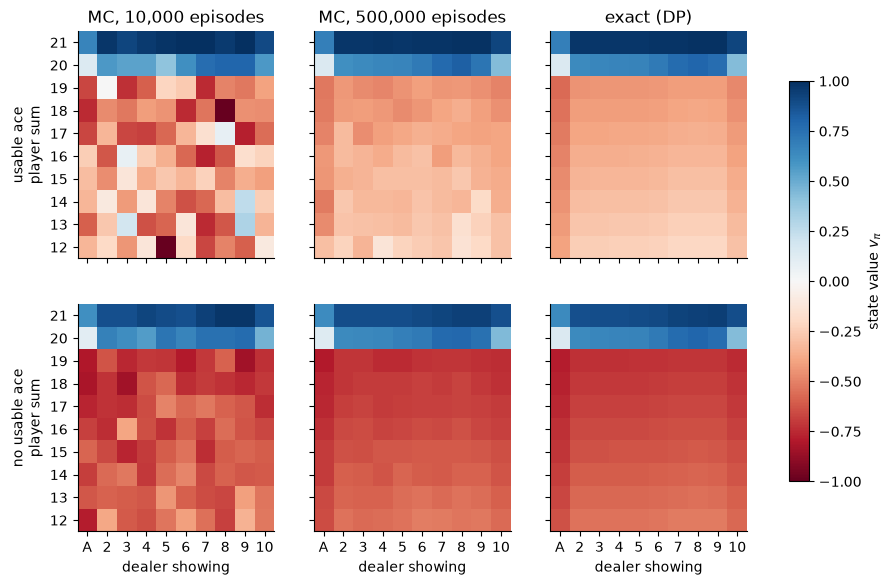

In [10]:
rng = np.random.default_rng(SEED_PREDICT)
idx, ret, ends = first_visit_mc(N_LARGE, fixed_policy, card_stream(rng))
v_small, _, _ = estimate(idx, ret, ends, N_SMALL)
v_large, n_large, var_large = estimate(idx, ret, ends, N_LARGE)
for n_ep, v in ((N_SMALL, v_small), (N_LARGE, v_large)):
    err = np.abs(v - v_exact)
    print(
        f"After {n_ep:>7} episodes: mean absolute error {np.nanmean(err):.4f} (no usable ace {np.nanmean(err[:, :, 0]):.4f}, "
        f"usable ace {np.nanmean(err[:, :, 1]):.4f}), largest {np.nanmax(err):.3f}, unvisited states {int(np.isnan(v).sum())}"
    )
print(f"Visits per state after {N_LARGE} episodes: median {int(np.median(n_large))}, fewest {n_large.min()}, most {n_large.max()}")
print("Checkpoint: the larger run is closer to the exact values in mean absolute error:", np.nanmean(np.abs(v_large - v_exact)) < np.nanmean(np.abs(v_small - v_exact)))
heatmaps([v_small, v_large, v_exact], [f"MC, {N_SMALL:,} episodes", f"MC, {N_LARGE:,} episodes", "exact (DP)"], "state value $v_\\pi$")

### Reading the result

- After 10,000 episodes the mean absolute error over the 200 states is 0.1189 (0.0598 without a usable ace, 0.1780 with one); after 500,000 it is 0.0182 (0.0088 and 0.0276). The largest single error falls from 0.762 to 0.113. Both counts are the ones used in the book, so nothing is scaled down here.
- The heatmaps show the same shape as the exact values: positive values for sums 20 and 21, where the policy sticks (close to +1 for 21), and negative values for lower sums, where it hits. After 10,000 episodes the maps are ragged, most of all with a usable ace; after 500,000 they are smooth and hard to tell from the exact panel.
- States with a usable ace are rarer, so their estimates stay noisier: after 500,000 episodes the least-visited state has 202 visits against a median of 3,735, and the mean error with a usable ace is about three times that without. The book makes the same observation.
- Where the notebook differs from the book: the estimates are heatmaps instead of surfaces, and the book leaves two rules open. A dealer natural against a non-natural player 21 is taken as a draw (the closer-sum rule), and there is no peeking (see the game rules above). The book does say that a player natural wins unless the dealer has one.
- Naturals enter the three Monte Carlo methods differently. In this section a natural counts as a visit to the state (21, dealer card, usable ace) with its own return, so the state is the one the book defines. With exploring starts a natural cannot occur, because games start in a chosen state. In the epsilon-soft method naturals are left out of the action values, since no decision is made in them.

## 4. The error shrinks as one over the square root of the sample size

Each return is an independent sample with finite variance, so for a state with $n$ returns the estimate's error has standard deviation $\sigma_s / \sqrt{n}$, where $\sigma_s$ is the standard deviation of that state's returns.
The exact values let us measure the actual error and compare it with this prediction, using the prefixes of the one run of the previous section.

- Only states expected to be visited at least `MIN_VISITS` times within the first `N_SMALL` episodes are used (118 of the 200); the choice depends on the exact visit probabilities, not on the sampled errors. The 82 rarer states are not covered by these checks.
- Predicted root-mean-square error (RMSE) at $n$ episodes: $\sqrt{\text{mean}_s\, \hat\sigma_s^2 / n_s}$, with $\hat\sigma_s^2$ the sample variance of the returns and $n_s$ the state's visit count at that point.
- A standardized error $z_s = (V(s) - v_\pi(s)) / (\hat\sigma_s / \sqrt{n_s})$ should look like a standard normal draw. Requiring all 118 to lie within 3 would fail by chance about 27% of runs (118 x 0.0027 = 0.32 expected exceedances), so the check requires a share of at least `Z_SHARE_MIN` = 0.97 instead.

118 of 200 states used
 episodes     RMSE  predicted  ratio  RMSE*sqrt(n)
    10000   0.0771     0.0700   1.10         7.708
    20000   0.0530     0.0497   1.07         7.492
    50000   0.0317     0.0314   1.01         7.096
   100000   0.0220     0.0222   0.99         6.955
   200000   0.0156     0.0156   1.00         6.994
   500000   0.0109     0.0099   1.10         7.704
Fitted log-log slope of the RMSE against the sample size: -0.508 (theory -0.5)
Standardized errors at 500000 episodes: share with |z| < 2 is 0.941 (normal: 0.954), with |z| < 3 is 1.000 (normal: 0.997)
Checkpoint: observed RMSE within 25% of the prediction at every size: True


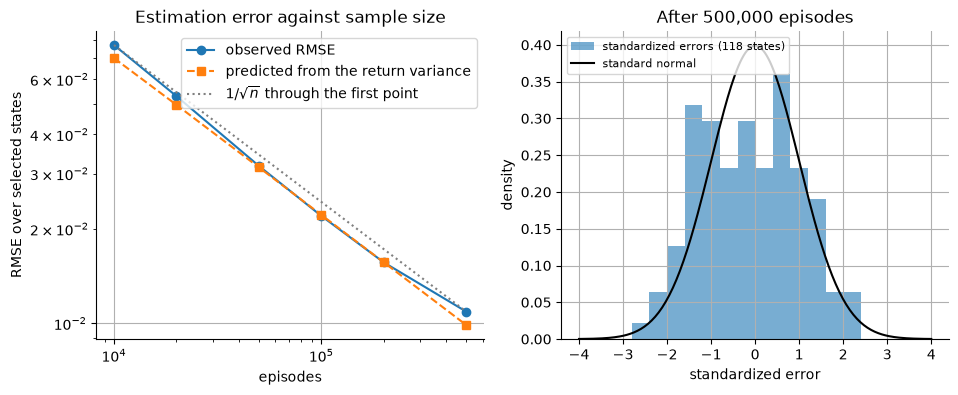

In [11]:
visit_full = visit.copy()
visit_full[9, 1] += p_natural
selected = visit_full[:, None, :] * P_CARD[None, :, None] * N_SMALL >= MIN_VISITS
rows = []
for n in N_GRID:
    v_n, c_n, _ = estimate(idx, ret, ends, n)
    observed = np.sqrt(np.mean((v_n - v_exact)[selected] ** 2))
    predicted = np.sqrt(np.mean((var_large[selected] / c_n[selected])))
    rows.append((n, observed, predicted))
rows = np.array(rows)
slope = np.polyfit(np.log(rows[:, 0]), np.log(rows[:, 1]), 1)[0]
z = ((v_large - v_exact) / np.sqrt(var_large / n_large))[selected]
z_share = np.mean(np.abs(z) < Z_LIMIT)
print(f"{int(selected.sum())} of {N_STATES} states used")
print(f"{'episodes':>9}{'RMSE':>9}{'predicted':>11}{'ratio':>7}{'RMSE*sqrt(n)':>14}")
for n, obs, pred in rows:
    print(f"{int(n):>9}{obs:>9.4f}{pred:>11.4f}{obs / pred:>7.2f}{obs * np.sqrt(n):>14.3f}")
print(f"Fitted log-log slope of the RMSE against the sample size: {slope:.3f} (theory -0.5)")
print(f"Standardized errors at {N_LARGE} episodes: share with |z| < 2 is {np.mean(np.abs(z) < 2):.3f} (normal: 0.954), with |z| < {Z_LIMIT} is {z_share:.3f} (normal: 0.997)")
print(f"Checkpoint: observed RMSE within {RMSE_RATIO_TOL:.0%} of the prediction at every size:", bool(np.all(np.abs(rows[:, 1] / rows[:, 2] - 1) < RMSE_RATIO_TOL)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.loglog(rows[:, 0], rows[:, 1], "o-", label="observed RMSE")
ax1.loglog(rows[:, 0], rows[:, 2], "s--", label="predicted from the return variance")
ax1.loglog(rows[:, 0], rows[0, 1] * np.sqrt(rows[0, 0] / rows[:, 0]), ":", color="gray", label=r"$1/\sqrt{n}$ through the first point")
ax1.set(xlabel="episodes", ylabel="RMSE over selected states", title="Estimation error against sample size")
ax1.legend()
grid = np.linspace(-4, 4, 200)
ax2.hist(z, bins=np.linspace(-4, 4, 21), density=True, alpha=0.6, label=f"standardized errors ({z.size} states)")
ax2.plot(grid, stats.norm.pdf(grid), "k", label="standard normal")
ax2.set(xlabel="standardized error", ylabel="density", title=f"After {N_LARGE:,} episodes")
ax2.legend(loc="upper left", fontsize=8)
plt.show()

### Reading the result

- The 118 states selected have a root-mean-square error of 0.0771 at 10,000 episodes and 0.0109 at 500,000: a factor of 7.1, matching the square root of the 50-fold increase in episodes (7.07). The product of the error and $\sqrt{n}$ stays between 6.955 and 7.708, and the fitted log-log slope is -0.508 against the theoretical -0.5.
- The prediction from the sampled return variances is close at every size: the observed error is between 0.99 and 1.10 times it, so the error follows the formula $\sigma_s/\sqrt{n_s}$ and not only its slope.
- The standardized errors behave like normal draws: 0.941 lie within 2 (0.954 expected for a normal) and 1.000 within 3. This also covers the soft 21 mixture from the exact dynamic programming: a wrong mixture there would show up as large standardized errors, and none does. It covers only the 118 well-visited states.
- The tolerances are derived, not tuned: the RMSE over 118 states has a relative sampling error of about $1/\sqrt{2 \cdot 118}$ = 6.5%, so 25% is about four times that; the slope over a 50-fold range of sample sizes has a standard error of a few hundredths if the points were independent, so 0.1 is a generous margin because the points are correlated prefixes of one run.
- In the left plot the observed and predicted curves are parallel to the dotted $1/\sqrt{n}$ line; the right histogram of 118 values is coarse but centred and roughly bell-shaped.
- The sample sizes are prefixes of one run, so the errors at different sizes are not independent; the notebook shows agreement with the formula and does not turn the slope into a hypothesis test.

## 5. Monte Carlo control with exploring starts

Without a model, improving a policy needs action values $q(s, a)$: the policy can then be made greedy, $\pi(s) = \arg\max_a Q(s, a)$, by comparing actions directly.
Monte Carlo with exploring starts (Monte Carlo ES) alternates evaluation and improvement after every episode:

1. Pick a starting state $S_0$ and action $A_0$ at random, so every pair has a chance to start a game.
2. Play the rest of the game with the current $\pi$.
3. For each pair $(s, a)$ in the game, append the return $G$ to $Returns(s, a)$ and set $Q(s, a)$ to its average.
4. For each state $s$ in the game, set $\pi(s) \leftarrow \arg\max_a Q(s, a)$.

- All returns of a pair are averaged, whatever policy was in force when they occurred.
- Start: the 200 states and the 2 actions are drawn uniformly (the dealer's showing card uniformly over the 10 values); $Q$ starts at zero and $\pi$ at the fixed policy of the previous sections. Ties in $\arg\max$ go to stick.
- Truth: the exact optimal values, $q_*$ and $\pi_*$. The book calls convergence of this algorithm unproved, so `N_RUNS` independent runs (seeds spawned from one named seed) show a tendency, not a proof.
- The policy is stored as a table and snapshots of it are taken during each run to see how fast it settles.

In [12]:
def child_rngs(seed: int, n: int) -> list:
    """`n` independent generators spawned from one named seed."""
    return [np.random.default_rng(c) for c in np.random.SeedSequence(seed).spawn(n)]


def summarize(q_sum: list, q_sq: list, q_n: list) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Mean, count and sample standard deviation of the returns of every state-action pair."""
    n, shape = np.maximum(q_n, 1), (10, 10, 2, 2)
    mean = np.array(q_sum) / n
    sd = np.sqrt(np.maximum(np.array(q_sq) / n - mean**2, 0))
    return mean.reshape(shape), np.array(q_n).reshape(shape), sd.reshape(shape)


def mc_exploring_starts(starts: list, cards) -> tuple[np.ndarray, np.ndarray, np.ndarray, list]:
    """Monte Carlo ES: Q[sum, dealer, usable, action], visit counts, return standard deviations and policy snapshots (hit = 1)."""
    q_sum, q_sq, q_n, q = [0.0] * N_PAIRS, [0.0] * N_PAIRS, [0] * N_PAIRS, [0.0] * N_PAIRS
    pi = [STICK if t >= FIXED_STICK else HIT for t in SUMS for _ in range(20)]

    def choose(t: int, d: int, u: int) -> int:
        return pi[state_index(t, d, u)]

    snapshots = []
    for i, k in enumerate(starts, 1):
        pair = k >> 1
        visits, g, _ = episode(choose, cards, ((pair >> 1) // 10 + 12, (pair >> 1) % 10 + 1, pair & 1, k & 1))
        for t, d, u, a in visits:
            s = state_index(t, d, u)
            j = 2 * s + a
            q_n[j] += 1
            q_sum[j] += g
            q_sq[j] += g * g
            q[j] = q_sum[j] / q_n[j]
            pi[s] = HIT if q[2 * s + 1] > q[2 * s] else STICK
        if i % SNAPSHOT_EVERY == 0:
            snapshots.append(np.array(pi).reshape(10, 10, 2))
    return (*summarize(q_sum, q_sq, q_n), snapshots)

In [13]:
def shortfall(pi: np.ndarray, q_true: np.ndarray) -> np.ndarray:
    """Exact loss in action value, per state, from taking the action `pi` instead of the best one."""
    return q_true.max(axis=-1) - np.take_along_axis(q_true, pi[..., None], axis=-1)[..., 0]


def mistakes_within_noise(pi, pi_true, q_true, n_pair, sd_pair) -> bool:
    """Is every wrong decision's exact loss below `Z_LIMIT` standard errors of the estimated difference between its two action values?"""
    noise = Z_LIMIT * np.sqrt((sd_pair**2 / np.maximum(n_pair, 1)).sum(axis=-1))
    wrong = pi != pi_true
    return bool((shortfall(pi, q_true)[wrong] < noise[wrong]).all())


def assess(run: tuple, q_true: np.ndarray) -> dict:
    """Greedy policy of a run, its number of wrong states against the truth, their share of visits, and whether the mistakes lie within noise."""
    q, n, sd, _ = run
    pi, pi_true = (q[..., HIT] > q[..., STICK]).astype(int), (q_true[..., HIT] > q_true[..., STICK]).astype(int)
    visits, wrong = n.sum(axis=-1), pi != pi_true
    return {"pi": pi, "wrong": int(wrong.sum()), "share": visits[wrong].sum() / visits.sum(), "noise_ok": mistakes_within_noise(pi, pi_true, q_true, n, sd)}


def wrong_states(pi: np.ndarray, pi_true: np.ndarray, q_true: np.ndarray) -> list:
    """(sum, dealer card, usable ace, exact loss in action value) of every state where `pi` differs from `pi_true`."""
    gap = shortfall(pi, q_true)
    return [(int(SUMS[ti]), int(di) + 1, int(u), round(float(gap[ti, di, u]), 4)) for ti, di, u in zip(*np.nonzero(pi != pi_true))]


def counts_at(snapshots: list, pi_true: np.ndarray, episodes) -> list:
    """Number of states where the policy snapshot after each given episode count differs from `pi_true`."""
    return [int((snapshots[n // SNAPSHOT_EVERY - 1] != pi_true).sum()) for n in episodes]

In [14]:
def book_figure_policy() -> np.ndarray:
    """Hit table (1 = hit) read off the printed figure of the optimal policy."""
    t, d = SUMS[:, None, None], np.arange(1, 11)[None, :, None]
    hard = np.where(t >= 17, 0, np.where(t >= 13, ~((d >= 2) & (d <= 6)), np.where(t == 12, ~((d >= 4) & (d <= 6)), 1)))
    soft = np.where(t >= 19, 0, np.where(t == 18, ~((d >= 2) & (d <= 8)), 1))
    return np.where(np.arange(2)[None, None, :] == 1, soft, hard).astype(int)


def policy_text(pi: np.ndarray, reference: np.ndarray) -> str:
    """Policy as rows of S (stick) and H (hit) by player sum (top 21) and dealer card (A, 2..10); lower case = differs from `reference`."""
    out = []
    for u, name in ((1, "usable ace"), (0, "no usable ace")):
        out.append(f"{name:<14}dealer: A 2 3 4 5 6 7 8 9 10")
        for ti in range(9, -1, -1):
            cells = ["SH"[pi[ti, di, u]] if pi[ti, di, u] == reference[ti, di, u] else "sh"[pi[ti, di, u]] for di in range(10)]
            out.append(f"  sum {SUMS[ti]}:        " + " ".join(cells))
    return "\n".join(out)

3 runs of 1,000,000 episodes: states differing from the optimal policy [1, 2, 3]; expected return per game [-0.0433, -0.0434, -0.0436] (optimal -0.0431)
  run 1 wrong states (sum, dealer, usable ace, exact loss): [(13, 2, 0, 0.015)]
  run 2 wrong states (sum, dealer, usable ace, exact loss): [(12, 4, 0, 0.0025), (18, 10, 1, 0.0404)]
  run 3 wrong states (sum, dealer, usable ace, exact loss): [(12, 4, 0, 0.0025), (12, 5, 0, 0.0261), (16, 10, 0, 0.0065)]
Run 1: exact loss in action value at the wrong states at most 0.0150, mean over all states 0.00008; wrong decisions within sampling noise in every run: True
Run 1 action values: root-mean-square error against q_* over the 400 pairs 0.0153; visits per pair: median 2669, fewest 2356
Optimal policy found by Monte Carlo ES, run 1 (lower case: differs from the exact optimum)
usable ace    dealer: A 2 3 4 5 6 7 8 9 10
  sum 21:        S S S S S S S S S S
  sum 20:        S S S S S S S S S S
  sum 19:        S S S S S S S S S S
  sum 18:       

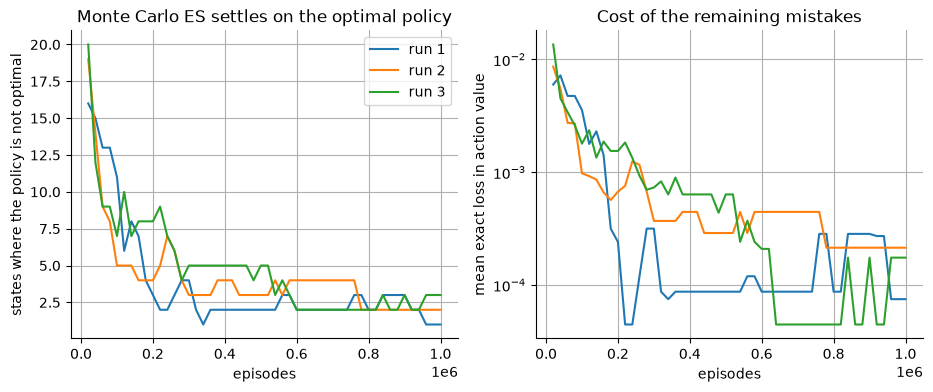

In [15]:
pi_opt = (q_opt[..., HIT] > q_opt[..., STICK]).astype(int)
es_runs = [mc_exploring_starts(rng.integers(0, N_PAIRS, N_ES).tolist(), card_stream(rng)) for rng in child_rngs(SEED_ES, N_RUNS)]
es = [assess(run, q_opt) for run in es_runs]
es_return = [exact_values(a["pi"].astype(float))[1] for a in es]
(q_es, n_es, _, snaps_es), pi_es = es_runs[0], es[0]["pi"]
gap_es = shortfall(pi_es, q_opt)
print(f"{N_RUNS} runs of {N_ES:,} episodes: states differing from the optimal policy {[a['wrong'] for a in es]}; expected return per game {[round(float(r), 4) for r in es_return]} (optimal {game_opt:.4f})")
for k, a in enumerate(es, 1):
    print(f"  run {k} wrong states (sum, dealer, usable ace, exact loss): {wrong_states(a['pi'], pi_opt, q_opt)}")
print(f"Run 1: exact loss in action value at the wrong states at most {gap_es.max():.4f}, mean over all states {gap_es.mean():.5f}; wrong decisions within sampling noise in every run: {all(a['noise_ok'] for a in es)}")
print(f"Run 1 action values: root-mean-square error against q_* over the {N_PAIRS} pairs {np.sqrt(np.mean((q_es - q_opt) ** 2)):.4f}; visits per pair: median {int(np.median(n_es))}, fewest {n_es.min()}")
print("Optimal policy found by Monte Carlo ES, run 1 (lower case: differs from the exact optimum)")
print(policy_text(pi_es, pi_opt))
book = book_figure_policy()
print(f"Soft 18 against a dealer ace: q_*(stick) = {q_opt[6, 0, 1, STICK]:.4f}, q_*(hit) = {q_opt[6, 0, 1, HIT]:.4f}")
report_es = range(REPORT_ES, N_ES + 1, REPORT_ES)
print(f"States where the policy is not optimal after {list(report_es)} episodes:")
for k, run in enumerate(es_runs, 1):
    print(f"  run {k}: {counts_at(run[3], pi_opt, report_es)}")
print(f"Checkpoint: the exact optimal policy equals the policy printed in the book's figure ({int((pi_opt != book).sum())} states differ):", bool((pi_opt == book).all()))

episodes_axis = SNAPSHOT_EVERY * np.arange(1, len(snaps_es) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for k, run in enumerate(es_runs, 1):
    ax1.plot(episodes_axis, [(s != pi_opt).sum() for s in run[3]], label=f"run {k}")
    ax2.plot(episodes_axis, [shortfall(s, q_opt).mean() for s in run[3]], label=f"run {k}")
ax2.set_yscale("symlog", linthresh=1e-5)
ax1.set(xlabel="episodes", ylabel="states where the policy is not optimal", title="Monte Carlo ES settles on the optimal policy")
ax2.set(xlabel="episodes", ylabel="mean exact loss in action value", title="Cost of the remaining mistakes")
ax1.legend()
plt.show()

### Reading the result

- Three runs of 1,000,000 exploring-start episodes (run 1 has a median of 2,669 visits per state-action pair, 2,356 at the fewest) end with 1, 2 and 3 of the 200 states differing from the exact optimal policy. The wrong states are near ties in action value: run 1 has hard 13 against a 2 (loss 0.0150); run 2 has hard 12 against a 4 (0.0025) and soft 18 against a 10 (0.0404); run 3 has hard 12 against a 4 (0.0025), hard 12 against a 5 (0.0261) and hard 16 against a 10 (0.0065).
- In every run the wrong decisions lie within 3 standard errors of the estimated gap between their two action values, using the actual standard deviations of the returns. What matters most is the return per game: the three policies return -0.0433, -0.0434 and -0.0436 against -0.0431 for optimal play, a shortfall of at most 0.0005.
- The count of wrong states, printed every 100,000 episodes, falls from 5 to 11 after 100,000 episodes to 1 to 3 after 1,000,000 (runs: 11, 3, 4, 2, 2, 2, 2, 2, 3, 1; 5, 4, 3, 4, 3, 4, 4, 2, 2, 2; 7, 8, 5, 5, 5, 2, 2, 2, 3, 3). It is not monotone (run 1 goes from 2 to 3 and back to 1), and no run reaches zero at the printed points, so the notebook shows a clear tendency toward the optimal policy within this budget, not convergence; the book itself calls convergence of this method unproved. Three runs also cannot show how often a run would end with zero wrong states.
- Run 1's action values have a root-mean-square error of 0.0153 against $q_*$, about what thousands of returns per pair allow (a standard error near 0.02 for returns in $[-1, 1]$). The right plot (symmetric logarithmic scale, linear near zero) shows the mean loss over all states falling, with bumps where a decision flips; this is read from the plot. A plausible reason for the flips is that near-tied states are decided by averages that differ by less than their noise; this explanation is not tested here.
- The exact optimal policy equals the policy in the book's figure of the optimal policy (read off the figure by eye), in all 200 states: stick on 17 or more without a usable ace, stick against 2 to 6 on 13 to 16, stick against 4 to 6 on 12; with a usable ace stick on 19 or more and on 18 against 2 to 8, and hit on 18 against an ace, 9 and 10.
- The book says this policy agrees with the standard basic strategy except at the leftmost notch of the usable-ace panel (18 against an ace). The exact computation confirms that the notch is real for these rules: for soft 18 against an ace $q_*$(stick) is -0.3771 and $q_*$(hit) is -0.3377, so hitting is better by 0.0394. The notebook does not contain the basic strategy table, so the agreement with it elsewhere is the book's statement and is not checked here.

## 6. On-policy first-visit Monte Carlo control with an epsilon-soft policy

Exploring starts need the simulator to start games anywhere; real play starts from the deal.
The alternative is to keep every action possible: an $\varepsilon$-soft policy gives each action probability at least $\varepsilon / |\mathcal{A}(s)|$, and the $\varepsilon$-greedy policy is the closest one to greedy:

$$
\pi(a \mid s) =
\begin{cases}
1 - \varepsilon + \varepsilon / |\mathcal{A}(s)| & a = \arg\max_{a'} Q(s, a') \\
\varepsilon / |\mathcal{A}(s)| & \text{otherwise}
\end{cases}
$$

- Play a full game from the deal with the current $\varepsilon$-greedy policy, average the returns after the first visit to each pair into $Q$, and let the policy follow the new $Q$; the policy is never stored, because computing the $\varepsilon$-greedy choice from the current $Q$ is the same thing.
- With two actions, hitting has probability $\varepsilon/2$ when stick is greedy, and $1 - \varepsilon/2$ when hit is greedy; here $\varepsilon$ = `EPS` = 0.1. $Q$ starts at zero (stick greedy).
- The method converges to the best $\varepsilon$-soft policy, not to the best policy, so the truth is the exact optimum among $\varepsilon$-soft policies, with the unconstrained optimum for comparison.
- As in the previous method, `N_RUNS` independent runs show how much the outcome depends on the seed.

In [16]:
def uniform_stream(rng: np.random.Generator):
    while True:
        yield from rng.random(CHUNK).tolist()


def hit_probability(pi: np.ndarray) -> np.ndarray:
    """Probability of hitting under the epsilon-greedy version of the greedy table `pi`."""
    return np.where(pi == HIT, 1 - EPS / 2, EPS / 2)


def mc_control_epsilon_soft(n_episodes: int, eps: float, cards, coins) -> tuple[np.ndarray, np.ndarray, np.ndarray, list]:
    """On-policy first-visit MC control: Q[sum, dealer, usable, action], visit counts, return standard deviations and greedy snapshots."""
    q_sum, q_sq, q_n, q = [0.0] * N_PAIRS, [0.0] * N_PAIRS, [0] * N_PAIRS, [0.0] * N_PAIRS

    def choose(t: int, d: int, u: int) -> int:
        r, s = next(coins), state_index(t, d, u)
        if r < eps:
            return HIT if r < eps / 2 else STICK
        return HIT if q[2 * s + 1] > q[2 * s] else STICK

    snapshots = []
    for i in range(1, n_episodes + 1):
        visits, g, natural = episode(choose, cards)
        if not natural:
            for t, d, u, a in visits:
                j = 2 * state_index(t, d, u) + a
                q_n[j] += 1
                q_sum[j] += g
                q_sq[j] += g * g
                q[j] = q_sum[j] / q_n[j]
        if i % SNAPSHOT_EVERY == 0:
            snapshots.append((np.array(q[1::2]) > np.array(q[0::2])).astype(int).reshape(10, 10, 2))
    return (*summarize(q_sum, q_sq, q_n), snapshots)

3 runs of 6,000,000 games: states differing from the best epsilon-soft policy [1, 1, 1], holding [0.0072, 0.0071, 0.0071] of the visits
Expected return per game when played with exploration [-0.0731, -0.073, -0.073] (exact best epsilon-soft policy -0.0729); mistakes within sampling noise in every run: True
  run 1 wrong states (sum, dealer, usable ace, exact loss): [(12, 2, 0, 0.0157)]
  run 2 wrong states (sum, dealer, usable ace, exact loss): [(12, 3, 0, 0.0059)]
  run 3 wrong states (sum, dealer, usable ace, exact loss): [(12, 3, 0, 0.0059)]
Run 1: visits per state median 27128, fewest 2696; learned policy differs from the optimal policy in 3 states
The best epsilon-soft policy differs from the optimal policy in 2 states:
  sum 12, dealer 3, no usable ace: stick instead of hit (q_* gap 0.0186)
  sum 16, dealer 10, no usable ace: stick instead of hit (q_* gap 0.0065)
States where the greedy policy differs from the best epsilon-soft policy after [500000, 1000000, 1500000, 2000000, 250

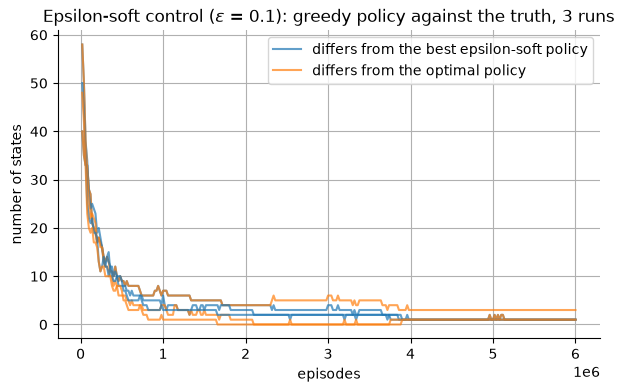

In [17]:
soft_runs = [mc_control_epsilon_soft(N_SOFT, EPS, card_stream(rng), uniform_stream(rng)) for rng in child_rngs(SEED_SOFT, N_RUNS)]
q_eps, game_eps = exact_values(eps=EPS)
pi_eps = (q_eps[..., HIT] > q_eps[..., STICK]).astype(int)
soft = [assess(run, q_eps) for run in soft_runs]
soft_play = [exact_values(hit_probability(a["pi"]))[1] for a in soft]
(q_soft, n_soft, _, snaps_soft), pi_soft = soft_runs[0], soft[0]["pi"]
print(f"{N_RUNS} runs of {N_SOFT:,} games: states differing from the best epsilon-soft policy {[a['wrong'] for a in soft]}, holding {[round(float(a['share']), 4) for a in soft]} of the visits")
print(f"Expected return per game when played with exploration {[round(float(r), 4) for r in soft_play]} (exact best epsilon-soft policy {game_eps:.4f}); mistakes within sampling noise in every run: {all(a['noise_ok'] for a in soft)}")
for k, a in enumerate(soft, 1):
    print(f"  run {k} wrong states (sum, dealer, usable ace, exact loss): {wrong_states(a['pi'], pi_eps, q_eps)}")
print(f"Run 1: visits per state median {int(np.median(n_soft.sum(axis=-1)))}, fewest {int(n_soft.sum(axis=-1).min())}; learned policy differs from the optimal policy in {int((pi_soft != pi_opt).sum())} states")
print(f"The best epsilon-soft policy differs from the optimal policy in {int((pi_eps != pi_opt).sum())} states:")
for ti, di, u in zip(*np.nonzero(pi_eps != pi_opt)):
    print(f"  sum {SUMS[ti]}, dealer {di + 1}, {'usable ace' if u else 'no usable ace'}: {('stick', 'hit')[pi_eps[ti, di, u]]} instead of {('stick', 'hit')[pi_opt[ti, di, u]]} (q_* gap {abs(q_opt[ti, di, u, 0] - q_opt[ti, di, u, 1]):.4f})")
report_soft = range(REPORT_SOFT, N_SOFT + 1, REPORT_SOFT)
print(f"States where the greedy policy differs from the best epsilon-soft policy after {list(report_soft)} games:")
for k, run in enumerate(soft_runs, 1):
    print(f"  run {k}: {counts_at(run[3], pi_eps, report_soft)}")
print("Greedy policy learned in run 1 (lower case: differs from the best epsilon-soft policy)")
print(policy_text(pi_soft, pi_eps))
returns = {
    "fixed policy": game_fixed,
    "epsilon-soft, played with exploration": soft_play[0],
    "epsilon-soft, played greedily": exact_values(pi_soft.astype(float))[1],
    "MC ES policy, played greedily": es_return[0],
    "optimal policy, played greedily": game_opt,
}
for name, value in returns.items():
    print(f"Expected return per game, run 1, {name}: {value:.4f}")
print("Checkpoint: playing with exploration costs return relative to playing greedily:", returns["epsilon-soft, played with exploration"] < returns["epsilon-soft, played greedily"])

fig, ax = plt.subplots()
axis_soft = SNAPSHOT_EVERY * np.arange(1, len(snaps_soft) + 1)
for k, run in enumerate(soft_runs):
    ax.plot(axis_soft, [(s != pi_eps).sum() for s in run[3]], color="C0", alpha=0.7, label="differs from the best epsilon-soft policy" if k == 0 else None)
    ax.plot(axis_soft, [(s != pi_opt).sum() for s in run[3]], color="C1", alpha=0.7, label="differs from the optimal policy" if k == 0 else None)
ax.set(xlabel="episodes", ylabel="number of states", title=f"Epsilon-soft control ($\\varepsilon$ = {EPS}): greedy policy against the truth, {N_RUNS} runs")
ax.legend()
plt.show()

### Reading the result

- Three runs of 6,000,000 games from the deal each end with exactly 1 of the 200 states differing from the best epsilon-soft policy: hard 12 against a 2 in run 1 (loss 0.0157 in epsilon-soft action value) and hard 12 against a 3 in runs 2 and 3 (0.0059). These states hold 0.0072, 0.0071 and 0.0071 of all visits, under the 2% limit, and the wrong decisions are within 3 standard errors of the estimated gap in every run.
- Played with exploration, the learned policies return -0.0731, -0.0730 and -0.0730 per game against -0.0729 for the exact best epsilon-soft policy, a shortfall of at most 0.0001. In run 1, played greedily it returns -0.0439 against -0.0433 for the exploring-starts policy of run 1 and -0.0431 for optimal play. Exploration costs about 0.029 per game (-0.0731 against -0.0439), the price of removing the need for exploring starts.
- The count of states differing from the best epsilon-soft policy, printed every 500,000 games, ends at 1 in every run from 4,000,000 games on (run 1: 9, 7, 5, 4, 3, 4, 3, 1, 1, 1, 1, 1; run 2: 8, 6, 3, 3, 2, 2, 2, 1, 1, 1, 1, 1; run 3: 9, 3, 3, 2, 2, 2, 2, 1, 1, 1, 1, 1). It is not monotone in run 1 (3 to 4), so reaching a stable count is a tendency across three runs, not a guarantee; between the printed points it is read from the plot.
- The remaining mistakes are near ties that cost little. A likely reason is that a state's non-greedy action is tried only with probability 0.05 per visit, so its average stays noisy for long; this explanation is not tested here. The run length of 6,000,000 games is a tuning choice made after seeing that 2,000,000 games were not enough (2 to 4 states still differed there); even at 6,000,000 one state differs.
- The best epsilon-soft policy is not the optimal policy: it sticks instead of hitting at hard 12 against a 3 (gap 0.0186) and at hard 16 against a 10 (gap 0.0065), both near ties, because exploration changes what a hit is worth. Run 1's learned policy differs from the optimum in 3 states (the two above plus its one error).
- The plot shows, for each run, the number of states differing from the best epsilon-soft policy (blue) falling and ending at 1, while the number differing from the optimal policy (orange) ends at 3, 1 and 1.
- The book gives no blackjack result for this method; the comparison here is against the exact truth only.

## 7. Checkpoints

In [18]:
err_small, err_large = np.nanmean(np.abs(v_small - v_exact)), np.nanmean(np.abs(v_large - v_exact))
checks = [
    (f"simulated dealer outcomes match the exact ones within {DEALER_Z_LIMIT} standard errors", worst < DEALER_Z_LIMIT),
    ("hard 21 against a dealer 6 equals one minus the dealer's chance of 21", bool(np.isclose(v_exact[9, 5, 0], 1 - f6[4]))),
    ("prediction error falls at least 5-fold from 10,000 to 500,000 episodes", err_small > 5 * err_large),
    (f"after 500,000 episodes at least {Z_SHARE_MIN:.0%} of the well-visited states are within {Z_LIMIT} standard errors", z_share >= Z_SHARE_MIN),
    (f"the root-mean-square error is within {RMSE_RATIO_TOL:.0%} of the prediction at every sample size", bool(np.all(np.abs(rows[:, 1] / rows[:, 2] - 1) < RMSE_RATIO_TOL))),
    (f"the log-log slope of the error against the sample size is within {SLOPE_TOL} of -0.5", abs(slope + 0.5) < SLOPE_TOL),
    ("the exact optimal policy equals the policy in the book's figure", bool((pi_opt == book).all())),
    (f"in every run Monte Carlo ES plays within {ES_RETURN_TOL} of the optimal return per game", max(game_opt - r for r in es_return) < ES_RETURN_TOL),
    ("in every run the Monte Carlo ES mistakes lie within sampling noise", all(a["noise_ok"] for a in es)),
    (f"in every run epsilon-soft control plays within {SOFT_RETURN_TOL} of the best epsilon-soft return per game", max(game_eps - r for r in soft_play) < SOFT_RETURN_TOL),
    ("in every run the epsilon-soft mistakes lie within sampling noise", all(a["noise_ok"] for a in soft)),
    (f"in every run the epsilon-soft mistakes hold under {MISTAKE_VISIT_SHARE:.0%} of the visits", all(a["share"] < MISTAKE_VISIT_SHARE for a in soft)),
    ("playing with exploration costs return relative to playing greedily", returns["epsilon-soft, played with exploration"] < returns["epsilon-soft, played greedily"]),
]
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)


def span(values: list) -> str:
    return f"{min(values)}-{max(values)}"


print(f"\n{'method':<58}{'result':>10}{'truth':>9}")
for name, result, truth in [
    (f"prediction, mean absolute error, {N_SMALL:,} episodes", f"{err_small:.4f}", "0"),
    (f"prediction, mean absolute error, {N_LARGE:,} episodes", f"{err_large:.4f}", "0"),
    ("prediction, error slope against sample size", f"{slope:.3f}", "-0.5"),
    (f"Monte Carlo ES, states differing from optimum ({N_RUNS} runs)", span([a["wrong"] for a in es]), "0"),
    ("Monte Carlo ES, worst return shortfall per game", f"{max(game_opt - r for r in es_return):.4f}", "0"),
    (f"epsilon-soft, states differing from best soft ({N_RUNS} runs)", span([a["wrong"] for a in soft]), "0"),
    ("epsilon-soft, worst return shortfall per game", f"{max(game_eps - r for r in soft_play):.4f}", "0"),
]:
    print(f"{name:<58}{result:>10}{truth:>9}")

PASS simulated dealer outcomes match the exact ones within 4 standard errors
PASS hard 21 against a dealer 6 equals one minus the dealer's chance of 21
PASS prediction error falls at least 5-fold from 10,000 to 500,000 episodes
PASS after 500,000 episodes at least 97% of the well-visited states are within 3 standard errors
PASS the root-mean-square error is within 25% of the prediction at every sample size
PASS the log-log slope of the error against the sample size is within 0.1 of -0.5
PASS the exact optimal policy equals the policy in the book's figure
PASS in every run Monte Carlo ES plays within 0.002 of the optimal return per game
PASS in every run the Monte Carlo ES mistakes lie within sampling noise
PASS in every run epsilon-soft control plays within 0.001 of the best epsilon-soft return per game
PASS in every run the epsilon-soft mistakes lie within sampling noise
PASS in every run the epsilon-soft mistakes hold under 2% of the visits
PASS playing with exploration costs return 